In [3]:
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, auc, roc_auc_score

# Ensure working directory is the main project root
if os.getcwd().endswith("notebooks"):
    os.chdir("..")

print("Current working directory:", os.getcwd())

Current working directory: /Users/palakgupta/Desktop/card-fraud-triage


In [4]:
# Load the scaler and trained GMM model
scaler = joblib.load('models/scaler.joblib')
best_gmm = joblib.load('models/best_gmm.joblib')

# Load the test dataset
test_df = pd.read_csv('data/processed/test.csv')

# Separate features (X) and true labels (y)
# (Assuming your target column is named 'Class' where 1 = fraud, 0 = legit)
X_test = test_df.drop(columns=['Class'])
y_test = test_df['Class']

# Scale test features using the saved scaler
X_test_scaled = scaler.transform(X_test)

print("Data and models loaded successfully!")
print(f"Test features shape: {X_test_scaled.shape}")

Data and models loaded successfully!
Test features shape: (56962, 30)


In [5]:
# GMM score_samples returns log-likelihoods. 
# Lower log-likelihood = higher anomaly likelihood (potential fraud).
# We convert it to an anomaly score by taking the negative log-likelihood.
log_likelihoods = best_gmm.score_samples(X_test_scaled)
anomaly_scores = -log_likelihoods

# Calculate ROC-AUC and PR-AUC
roc_auc = roc_auc_score(y_test, anomaly_scores)
precision, recall, thresholds = precision_recall_curve(y_test, anomaly_scores)
pr_auc = auc(recall, precision)

print(f"Test ROC-AUC: {roc_auc:.4f}")
print(f"Test PR-AUC:  {pr_auc:.4f}")

Test ROC-AUC: 0.9065
Test PR-AUC:  0.3622


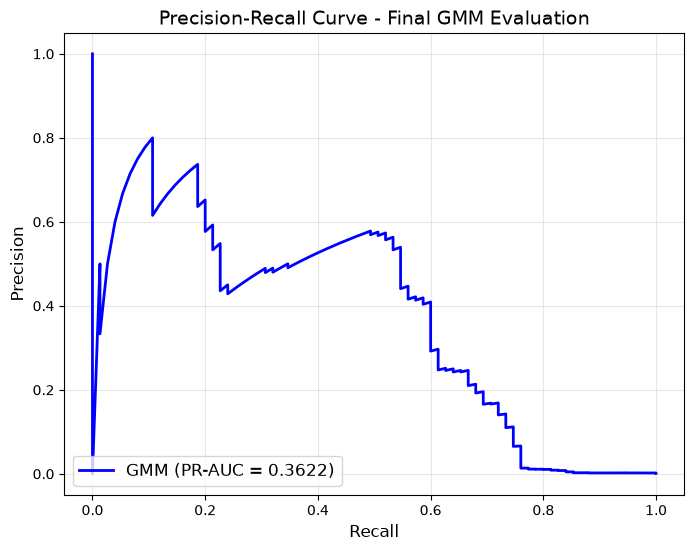

In [6]:
plt.figure(figsize=(8, 6))
plt.plot(recall, precision, color='blue', lw=2, label=f'GMM (PR-AUC = {pr_auc:.4f})')
plt.xlabel('Recall', fontsize=12)
plt.ylabel('Precision', fontsize=12)
plt.title('Precision-Recall Curve - Final GMM Evaluation', fontsize=14)
plt.legend(loc='lower left', fontsize=12)
plt.grid(True, alpha=0.3)
plt.show()